# Load libs

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
FlirtSources=os.environ["FlirtHome"]
FlirtData=os.environ["FlirtHome"]

In [2]:
print(FlirtSources, FlirtData)

/home/thibault.derrien/Documents/flirt1d.fresh /home/thibault.derrien/Documents/flirt1d.fresh


# Choose path

In [3]:
DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/03-NewRegime/08-NphTDDFT-film-WithImpact/0.5Jcm2-5umDepth"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/03-NewRegime/08-NphTDDFT-film-WithImpact"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/03-NewRegime/07-NphTDDFT-film-full"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/03-NewRegime/06-NphotonTDDFT-Ext"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/03-NewRegime/05-NphotonTDDFT-BL"
# DatabasePath=FlirtData+"/Results/03-NewRegime/04-NphotonTDDFT/"
# DatabasePath=FlirtData+"/Results/03-NewRegime/03-TeDebug/"
# DatabasePath=FlirtData+"/Results/03-NewRegime/01-NeExcDebug/"
# DatabasePath=FlirtData+"/Results/03-NewRegime/00-IntensityDebug/"
# DatabasePath=FlirtData+"/Results/03-NewRegime/02-Performance/02-GprofO3"
# DatabasePath=FlirtData+"/Results/03-NewRegime/"
# DatabasePath=OctopusData+"/09-Au/"
%cd $DatabasePath
%ls

/home/thibault.derrien/Documents/flirt1d.fresh/Results/03-NewRegime/08-NphTDDFT-film-WithImpact/0.5Jcm2-5umDepth
a.out*          Main0-02.vtk  Main0-11.vtk  Main0-20.vtk    PhaseKinetics0.dat
BonseSipe0.dat  Main0-03.vtk  Main0-12.vtk  Main0-21.vtk    Plasmon0.dat
Currents0.dat   Main0-04.vtk  Main0-13.vtk  Main0-22.vtk    TDDFT.csv@
Electrics0.dat  Main0-05.vtk  Main0-14.vtk  Main0.dat       TDDFT-nph.csv@
flirt.in        Main0-06.vtk  Main0-15.vtk  Material0.dat   Thermics0.dat
History.log     Main0-07.vtk  Main0-16.vtk  Maxwell0.dat    Time0.dat
Laser0.dat      Main0-08.vtk  Main0-17.vtk  Mesh0.dat
Main0-00.vtk    Main0-09.vtk  Main0-18.vtk  meshReason.dat
Main0-01.vtk    Main0-10.vtk  Main0-19.vtk  Papers0.dat


# Loading data

In [4]:
data=pd.read_csv("Time0.dat", sep="\t", header=0, skip_blank_lines=True)
datafull=data
data.describe(include="all")
data=data.rename(columns={"#Wavelength_m": "Wavelength_m"})
data=data.convert_dtypes()
data.dtypes

Wavelength_m                   float64
Time_s                         float64
Te_K                           float64
Ti_K                           float64
Ne_mmin3                       float64
Phase                            Int64
Intensity_Wm2                  float64
zMaxLiquid_m                     Int64
zMaxLiquidMixture_m            float64
zMaxGazMixture_m               float64
zMaxGaz_m                      float64
Source_Wm3                     float64
ElectricZ_Vm                     Int64
T                              float64
R                              float64
A                              float64
LaserEnergy_J                  float64
SurfaceTension                   Int64
ThermalEnergy_J                float64
totalsource_J                  float64
IonizationEnergy_J             float64
ElectronEnergy_J               float64
minReEps                       float64
Henthalpy_J                    float64
AbsProbe                       float64
ElectronicPotentialEnergy

# Plotting
## Ne(t)

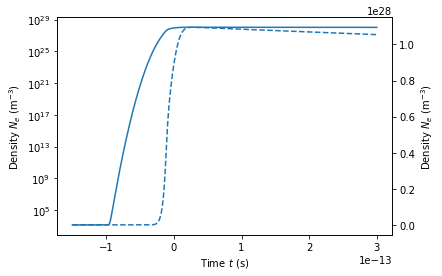

In [5]:
plt.figure()
ax1=plt.subplot(111)
ax1.semilogy(data.Time_s, data.Ne_mmin3, '-')
ax1.set_xlabel(r"Time $t$ (s)")
ax1.set_ylabel(r"Density $N_e$ (m$^{-3}$)")
ax12 = ax1.twinx()
ax12.plot(data.Time_s, data.Ne_mmin3, '--')
ax12.set_ylabel(r"Density $N_e$ (m$^{-3}$)")
plt.show()

## Te(t)

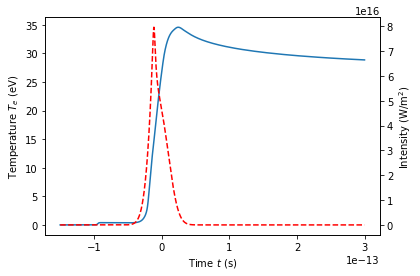

In [6]:
plt.figure()
ax1=plt.subplot(111)
ax1.plot(data.Time_s, data.Te_K/11600., '-')
plt.ylabel(r"Temperature $T_e$ (eV)")
ax12 = ax1.twinx()
ax12.plot(data.Time_s, data.Intensity_Wm2, 'r--')
ax1.set_xlabel(r"Time $t$ (s)")
ax12.set_ylabel(r"Intensity (W/m$^{2}$)")
plt.show()

# $\varepsilon(t)$

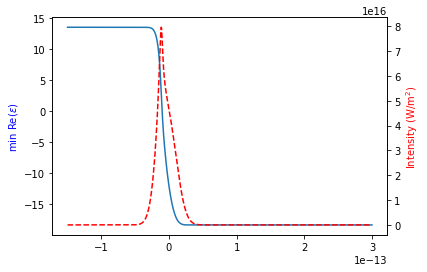

In [7]:
plt.figure()
ax1=plt.subplot(111)
ax1.plot(data.Time_s, data.minReEps, '-')
plt.ylabel(r"min Re$(\varepsilon)$", color="blue")
ax12 = ax1.twinx()
ax12.plot(data.Time_s, data.Intensity_Wm2, 'r--')
plt.xlabel(r"Time $t$ (s)")
plt.ylabel(r"Intensity (W/m$^{2}$)", color="red")
plt.show()

# Main output (t,z)

## Intensity(z;t)

In [ ]:
data=pd.read_csv("Main0.dat", sep="\t", header=0, skip_blank_lines=True)
datafull=data
data.describe(include="all")
data=data.rename(columns={"#Wavelength_m": "Wavelength_m"})
data=data.convert_dtypes()
data.dtypes

In [ ]:
# from scipy.constants import e
data=data[data.X_m==0] #select 1D
# set(data.Egap2d_J/e)

In [ ]:
data[data.Intensity_Wm3>0]

In [ ]:
data[data.Intensity_Wm3<0]

In [ ]:
print(np.min(data.Intensity_Wm3), np.max(data.Intensity_Wm3))
print(np.min(data.KeldyshTable_IntensityBranched), np.max(data.KeldyshTable_IntensityBranched))
print(np.max(data.KeldyshExcitationRate_wpi))

In [ ]:
pointsize=1
# data.plot.scatter(x="Time_s", y="Z_m", c="KeldyshExcitationRate_wpi")
# plt.scatter(data.Time_s, data.Z_m, c=(data.Egap2d_J/e), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=np.log10(data.Intensity_Wm3), s=pointsize, label="Intensity")
# plt.scatter(data.Time_s, data.Z_m, c=np.log10(data.Ne_mmin3), s=pointsize)
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
# plt.yscale("log")
# plt.xlim([-20e-15, -10e-15])
plt.colorbar()
plt.legend()
plt.show()

plt.figure()
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=np.log10(data.Ne_mmin3), s=pointsize, label="Ne")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
# plt.yscale("log")
# plt.xlim([-20e-15, -10e-15])
plt.colorbar()
plt.legend()
plt.show()



In [ ]:
plt.figure()
plt.title(r"$T_e$ (eV)")
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=(data.Te_K/11600), s=pointsize, label="Te")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
# plt.xlim([-20e-15, -10e-15])
plt.colorbar()
plt.legend()
plt.show()

plt.figure()
plt.title(r"$T_i$ (K)")
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=(data.Ti_K), s=pointsize, label="Ti")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
# plt.xlim([-20e-15, -10e-15])
plt.colorbar()
plt.legend()
plt.show()

In [ ]:
plt.figure()
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
# plt.scatter(data.Time_s, data.Z_m, c=(data.DielectricReal), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=np.log10(data.KeldyshExcitationRate_wpi), s=pointsize, label="Wpi")
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
# plt.xlim([-30e-15, 0e-15])
plt.legend()
plt.colorbar()
plt.show()

In [ ]:
plt.figure()
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
# plt.scatter(data.Time_s, data.Z_m, c=(data.DielectricReal), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=(data.NumberOfPhotons), s=pointsize, label="Number of photons")
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
# plt.xlim([-30e-15, 0e-15])
plt.legend()
plt.colorbar()
plt.show()

In [ ]:
RelError=(data.Intensity_Wm3-data.KeldyshTable_IntensityBranched)/data.Intensity_Wm3
plt.figure()
plt.scatter(data.Time_s, data.Z_m, c=RelError, s=pointsize, label="Relative error")
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
# plt.xlim([-30e-15, 0e-15])
plt.legend()
plt.colorbar()
plt.show()

In [ ]:
plt.figure()
plt.plot(data.Time_s, data.Intensity_Wm3, label="intensity")
plt.legend()

plt.figure()
plt.scatter(data.Z_m, data.Intensity_Wm3, label="intensity")
plt.legend()

In [ ]:
plt.figure()
plt.plot(data.Time_s, RelError, label="Error rel.")
plt.legend()

plt.figure()
plt.plot(data.Z_m, RelError, label="Error rel.")
plt.legend()

In [ ]:
plt.plot(data.Time_s, data.KeldyshExcitationRate_wpi, label="Wpi")
plt.legend()

In [ ]:
np.min(data.KeldyshExcitationRate_wpi)

In [ ]:
plt.plot(data.Time_s, data.Ne_mmin3, label="Ne")
plt.legend()